# Исследование объявлений о продаже квартир в Санкт-Петербурге и окрестностях

**Тип проекта:** исследовательский анализ данных (EDA)  
**Источник:** учебный датасет Яндекс Практикума с архивом объявлений. Данные исторические; выводы не следует трактовать как описание текущего рынка.

## Цель

Изучить распределения параметров квартир, определить признаки, связанные с ценой объекта, и посмотреть, как стоимость меняется в зависимости от локации и расстояния до центра Санкт-Петербурга.

## План
1. Загрузить данные и оценить качество.
2. Обработать типы, пропуски и очевидные аномалии, документируя допущения.
3. Добавить признаки для анализа.
4. Исследовать цену, площадь, сроки размещения, локации и расстояние до центра.
5. Сформулировать выводы и ограничения.

## 1. Загрузка и первичный осмотр

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

DATA_PATHS = [Path("data/real_estate_data.csv")]
data_path = next((p for p in DATA_PATHS if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("Поместите real_estate_data.csv в папку data/ рядом с ноутбуком или в /datasets/.")

data = pd.read_csv(data_path, sep="\t")

In [2]:
print(f"Размер исходной таблицы: {data.shape[0]:,} строк × {data.shape[1]} столбцов")
display(data.head())
data.info()

Размер исходной таблицы: 23,699 строк × 22 столбцов


,total_images,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,studio,open_plan,kitchen_area,balcony,locality_name,airports_nearest,cityCenters_nearest,parks_around3000,parks_nearest,ponds_around3000,ponds_nearest,days_exposition
0,20,"13,000,000.00",108.00,2019-03-07T00:00:00,3,2.70,16.00,51.00,8,NaN,False,False,25.00,NaN,Санкт-Петербург,"18,863.00","16,028.00",1.00,482.00,2.00,755.00,NaN
1,7,"3,350,000.00",40.40,2018-12-04T00:00:00,1,NaN,11.00,18.60,1,NaN,False,False,11.00,2.00,посёлок Шушары,"12,817.00","18,603.00",0.00,NaN,0.00,NaN,81.00
2,10,"5,196,000.00",56.00,2015-08-20T00:00:00,2,NaN,5.00,34.30,4,NaN,False,False,8.30,0.00,Санкт-Петербург,"21,741.00","13,933.00",1.00,90.00,2.00,574.00,558.00
3,0,"64,900,000.00",159.00,2015-07-24T00:00:00,3,NaN,14.00,NaN,9,NaN,False,False,NaN,0.00,Санкт-Петербург,"28,098.00","6,800.00",2.00,84.00,3.00,234.00,424.00
4,2,"10,000,000.00",100.00,2018-06-19T00:00:00,2,3.03,14.00,32.00,13,NaN,False,False,41.00,NaN,Санкт-Петербург,"31,856.00","8,098.00",2.00,112.00,1.00,48.00,121.00


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23699 entries, 0 to 23698
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   total_images          23699 non-null  int64  
 1   last_price            23699 non-null  float64
 2   total_area            23699 non-null  float64
 3   first_day_exposition  23699 non-null  object 
 4   rooms                 23699 non-null  int64  
 5   ceiling_height        14504 non-null  float64
 6   floors_total          23613 non-null  float64
 7   living_area           21796 non-null  float64
 8   floor                 23699 non-null  int64  
 9   is_apartment          2775 non-null   object 
 10  studio                23699 non-null  bool   
 11  open_plan             23699 non-null  bool   
 12  kitchen_area          21421 non-null  float64
 13  balcony               12180 non-null  float64
 14  locality_name         23650 non-null  object 
 15  airports_nearest   

In [3]:
missing = (data.isna().sum().rename("missing_count").to_frame())
missing["missing_pct"] = (missing["missing_count"] / len(data) * 100).round(2)
display(missing.sort_values("missing_pct", ascending=False))
print("Полных дубликатов:", data.duplicated().sum())

,missing_count,missing_pct
is_apartment,20924,88.29
parks_nearest,15620,65.91
ponds_nearest,14589,61.56
balcony,11519,48.61
ceiling_height,9195,38.80
airports_nearest,5542,23.38
cityCenters_nearest,5519,23.29
parks_around3000,5518,23.28
ponds_around3000,5518,23.28
days_exposition,3181,13.42


Полных дубликатов: 0


## 2. Подготовка данных

Пропуск не всегда означает ноль или отсутствие признака. Там, где заполнение неоднозначно, сохраняем пропуски; для `balcony` и `is_apartment` явно фиксируем допущения учебного решения.

In [4]:
data.columns = data.columns.str.lower()
# В исходном датасете имя столбца не содержит подчёркивания между city и centers.
data = data.rename(columns={"citycenters_nearest": "city_centers_nearest"})
data["first_day_exposition"] = pd.to_datetime(data["first_day_exposition"], errors="coerce")
data["locality_name"] = data["locality_name"].str.strip().str.lower()
data = data.drop_duplicates().copy()

# Допущения: отсутствие значения о балконе трактуем как отсутствие балкона;
# отсутствие отметки об апартаментах — как False. В реальном проекте эти допущения стоит проверить.
data["balcony"] = data["balcony"].fillna(0)
data["is_apartment"] = data["is_apartment"].fillna(False)

# Числовые поля приводим к числовому типу; некорректные значения становятся пропусками.
numeric_cols = ["last_price", "total_area", "living_area", "kitchen_area", "rooms", "ceiling_height",
                "floor", "floors_total", "airports_nearest", "city_centers_nearest", "parks_nearest",
                "ponds_nearest", "days_exposition", "balcony"]
for col in numeric_cols:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors="coerce")

# В исходных данных часть высот потолков записана с лишним разрядом (например, 25 вместо 2.5).
mask_height = data["ceiling_height"] >= 20
data.loc[mask_height, "ceiling_height"] = data.loc[mask_height, "ceiling_height"] / 10

# Убираем строки, где невозможно анализировать цену/площадь, и очевидно некорректные базовые значения.
rows_before = len(data)
data = data.dropna(subset=["last_price", "total_area", "first_day_exposition", "locality_name"]).copy()
data = data.query("last_price > 0 and total_area > 0 and rooms >= 0").copy()
data = data[data["ceiling_height"].isna() | data["ceiling_height"].between(2, 5)].copy()
data = data[data["floors_total"].isna() | (data["floors_total"] > 0)].copy()
print(f"Строк до базовой очистки: {rows_before:,}; после: {len(data):,}; исключено: {rows_before-len(data):,}")
print("Полных дубликатов после очистки:", data.duplicated().sum())

/tmp/ipykernel_1719/4037606297.py:11: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data["is_apartment"] = data["is_apartment"].fillna(False)


Строк до базовой очистки: 23,699; после: 23,633; исключено: 66
Полных дубликатов после очистки: 0


In [5]:
# Производные признаки
data["sqm_price"] = data["last_price"] / data["total_area"]
data["day_of_week"] = data["first_day_exposition"].dt.dayofweek
data["month"] = data["first_day_exposition"].dt.month
data["year"] = data["first_day_exposition"].dt.year

def classify_floor(row):
    if pd.isna(row["floor"]) or pd.isna(row["floors_total"]):
        return np.nan
    if row["floor"] == 1:
        return "первый"
    if row["floor"] == row["floors_total"]:
        return "последний"
    return "другой"

data["floor_type"] = data.apply(classify_floor, axis=1)
data["city_center_km"] = (data["city_centers_nearest"] / 1000).round(1)
display(data[["last_price", "total_area", "sqm_price", "rooms", "floor_type", "day_of_week", "month", "year", "city_center_km"]].head())

,last_price,total_area,sqm_price,rooms,floor_type,day_of_week,month,year,city_center_km
0,"13,000,000.00",108.00,"120,370.37",3,другой,3,3,2019,16.00
1,"3,350,000.00",40.40,"82,920.79",1,первый,1,12,2018,18.60
2,"5,196,000.00",56.00,"92,785.71",2,другой,3,8,2015,13.90
3,"64,900,000.00",159.00,"408,176.10",3,другой,4,7,2015,6.80
4,"10,000,000.00",100.00,"100,000.00",2,другой,1,6,2018,8.10


## 3. Распределения ключевых параметров

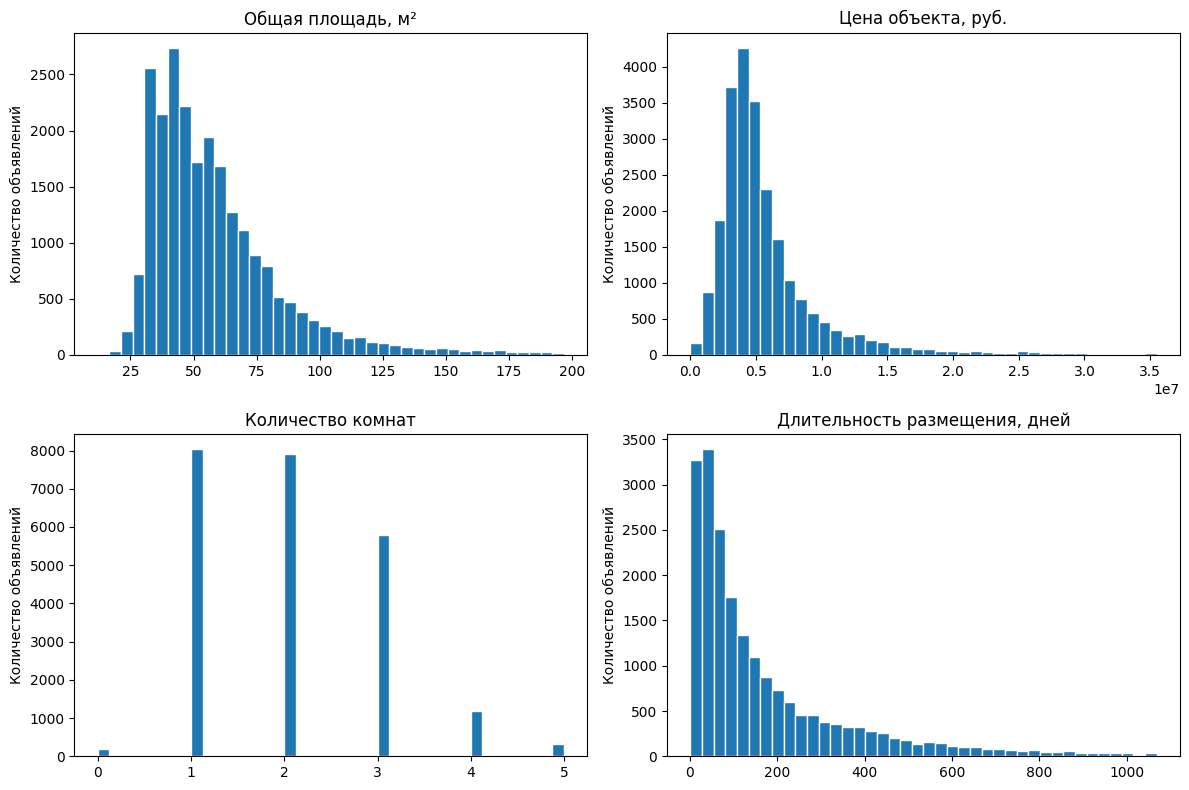

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col, title in zip(axes.flat,
                         ["total_area", "last_price", "rooms", "days_exposition"],
                         ["Общая площадь, м²", "Цена объекта, руб.", "Количество комнат", "Длительность размещения, дней"]):
    series = data[col].dropna()
    upper = series.quantile(0.99)
    ax.hist(series[series <= upper], bins=40, edgecolor="white")
    ax.set_title(title)
    ax.set_ylabel("Количество объявлений")
plt.tight_layout()

In [7]:
display(data[["total_area", "living_area", "kitchen_area", "last_price", "sqm_price", "rooms", "ceiling_height", "days_exposition"]].describe().T)

,count,mean,std,min,25%,50%,75%,max
total_area,"23,633.00",60.29,35.52,12.00,40.00,52.00,69.70,900.00
living_area,"21,737.00",34.43,21.98,2.00,18.60,30.00,42.30,409.70
kitchen_area,"21,369.00",10.56,5.89,1.30,7.00,9.10,12.00,112.00
last_price,"23,633.00","6,524,422.64","10,817,962.95","12,190.00","3,400,000.00","4,647,000.00","6,790,000.00","763,000,000.00"
sqm_price,"23,633.00","99,359.93","50,037.58",111.83,"76,584.51","95,000.00","114,253.39","1,907,500.00"
rooms,"23,633.00",2.07,1.08,0.00,1.00,2.00,3.00,19.00
ceiling_height,"14,473.00",2.73,0.27,2.00,2.51,2.65,2.80,5.00
days_exposition,"20,455.00",180.72,219.77,1.00,45.00,95.00,231.00,"1,580.00"


## 4. Какие признаки связаны с ценой?

,correlation_with_price
total_area,0.65
living_area,0.56
kitchen_area,0.52
rooms,0.36
city_centers_nearest,-0.21


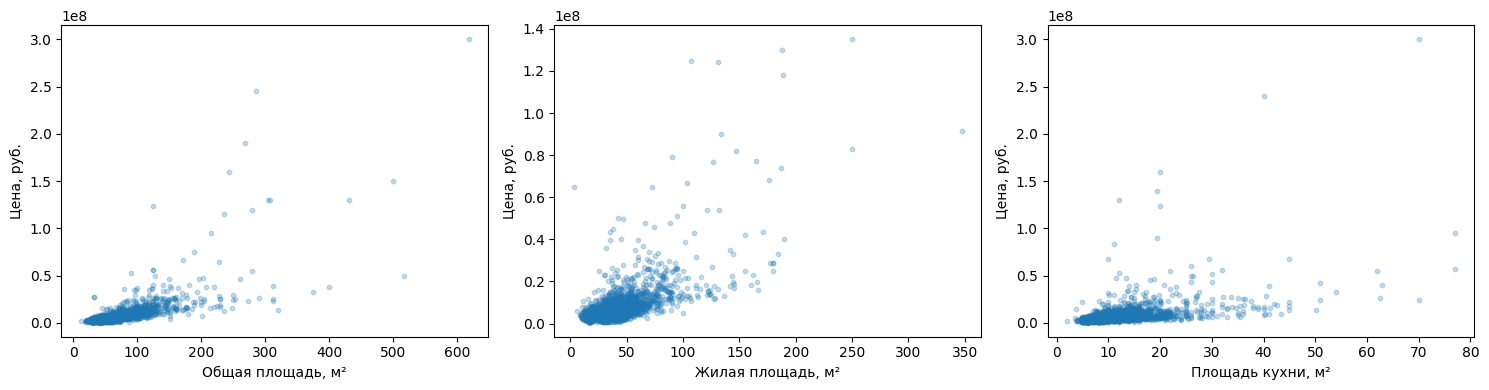

In [8]:
corr_cols = ["last_price", "total_area", "living_area", "kitchen_area", "rooms", "city_centers_nearest"]
correlations = data[corr_cols].corr(numeric_only=True)["last_price"].drop("last_price").sort_values(key=lambda s: s.abs(), ascending=False)
display(correlations.to_frame("correlation_with_price"))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, title in zip(axes, ["total_area", "living_area", "kitchen_area"], ["Общая площадь", "Жилая площадь", "Площадь кухни"]):
    plot_data = data[[col, "last_price"]].dropna()
    plot_data = plot_data.sample(min(4000, len(plot_data)), random_state=42)
    ax.scatter(plot_data[col], plot_data["last_price"], alpha=0.25, s=10)
    ax.set_xlabel(f"{title}, м²")
    ax.set_ylabel("Цена, руб.")
plt.tight_layout()

,listings,median_price,median_sqm_price
floor_type,,,
другой,17318,"4,843,000.00","98,275.86"
последний,3323,"4,300,000.00","87,705.14"
первый,2907,"3,900,000.00","81,250.00"


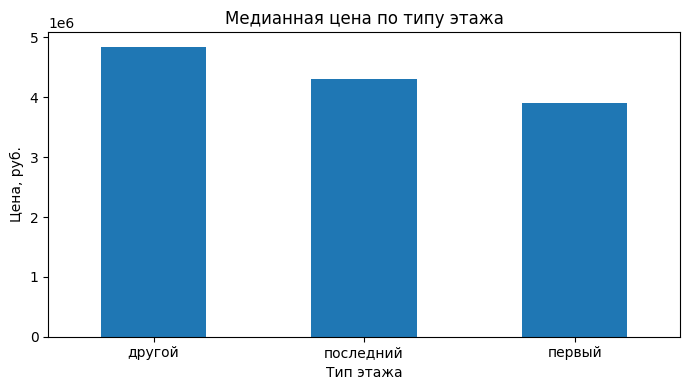

In [9]:
price_by_floor = data.groupby("floor_type", dropna=True).agg(
    listings=("last_price", "size"), median_price=("last_price", "median"), median_sqm_price=("sqm_price", "median")
).sort_values("median_price", ascending=False)
display(price_by_floor)
price_by_floor["median_price"].plot(kind="bar", figsize=(7, 4), title="Медианная цена по типу этажа", ylabel="Цена, руб.", xlabel="Тип этажа", rot=0)
plt.tight_layout()

## 5. Срок размещения объявления

,days_exposition
count,"20,455.00"
mean,180.72
std,219.77
min,1.00
25%,45.00
50%,95.00
75%,231.00
max,"1,580.00"


Медианная длительность размещения: 95 дней


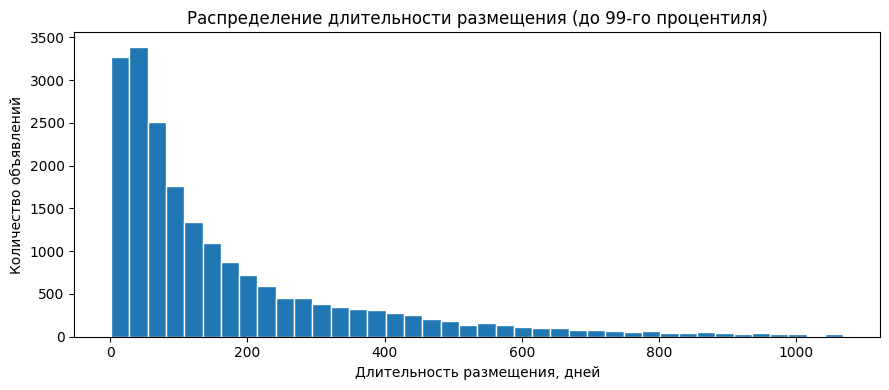

In [10]:
days = data["days_exposition"].dropna()
display(days.describe().to_frame("days_exposition"))
print(f"Медианная длительность размещения: {days.median():.0f} дней")
plt.figure(figsize=(9, 4))
plt.hist(days[days <= days.quantile(0.99)], bins=40, edgecolor="white")
plt.xlabel("Длительность размещения, дней")
plt.ylabel("Количество объявлений")
plt.title("Распределение длительности размещения (до 99-го процентиля)")
plt.tight_layout()

## 6. Локации и расстояние до центра

In [11]:
locality_stats = (data.groupby("locality_name")
    .agg(listings=("last_price", "size"), median_sqm_price=("sqm_price", "median"))
    .query("listings >= 10")
    .sort_values("listings", ascending=False))
display(locality_stats.head(10).round(0))

,listings,median_sqm_price
locality_name,,
санкт-петербург,15707,"104,762.00"
посёлок мурино,522,"85,878.00"
посёлок шушары,440,"76,876.00"
всеволожск,398,"65,789.00"
пушкин,369,"100,000.00"
колпино,338,"74,724.00"
посёлок парголово,327,"91,643.00"
гатчина,307,"67,797.00"
деревня кудрово,299,"91,860.00"


,listings,median_price,median_sqm_price
city_center_km,,,
0.30,11,"34,878,556.00","364,077.00"
0.40,10,"15,700,000.00","147,424.00"
0.60,16,"23,900,000.00","212,018.00"
0.70,16,"10,400,000.00","126,037.00"
0.80,12,"8,800,000.00","108,107.00"
1.10,17,"11,900,000.00","130,734.00"
1.20,41,"11,250,000.00","112,640.00"
1.30,36,"12,950,000.00","144,025.00"
1.40,21,"11,000,000.00","127,731.00"


Объявлений Санкт-Петербурга с известным расстоянием до центра: 15,646


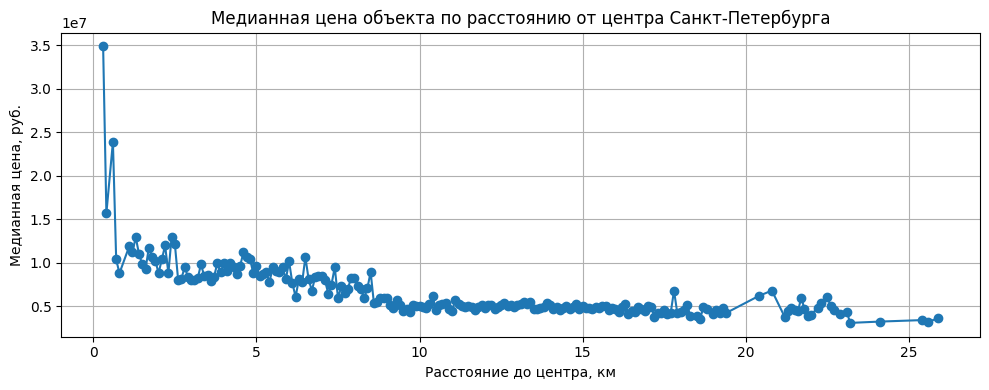

In [12]:
spb = data.loc[data["locality_name"].eq("санкт-петербург")].dropna(subset=["city_center_km"]).copy()
center_stats = spb.groupby("city_center_km").agg(
    listings=("last_price", "size"), median_price=("last_price", "median"), median_sqm_price=("sqm_price", "median")
)
# Для читаемости показываем километры, где достаточно наблюдений; дальние редкие значения могут быть нестабильны.
center_plot = center_stats.query("listings >= 10").sort_index()
display(center_plot.head(15).round(0))
center_plot["median_price"].plot(kind="line", marker="o", figsize=(10, 4), title="Медианная цена объекта по расстоянию от центра Санкт-Петербурга", xlabel="Расстояние до центра, км", ylabel="Медианная цена, руб.", grid=True)
plt.tight_layout()
print(f"Объявлений Санкт-Петербурга с известным расстоянием до центра: {len(spb):,}")

## 7. Итоговые выводы

- В исторической выборке цена объекта связана прежде всего с площадью; связь общей площади с ценой обычно сильнее, чем связь площади кухни или числа комнат. Корреляция не доказывает причинность.
- Цена зависит от типа этажа и расположения. Для сравнения локаций важно смотреть не только на среднюю цену, но и на число объявлений: оценки для редких групп нестабильны.
- Распределение длительности размещения имеет длинный хвост. Снятие объявления с публикации не обязательно означает завершённую продажу, поэтому `days_exposition` нельзя напрямую считать точным сроком сделки.
- Пропуски в `balcony` и `is_apartment` заполнены по допущению исходного учебного решения; это влияет на интерпретацию и должно быть указано.
- Данные исторические, а 2019 год неполный. Выводы нельзя переносить на современный рынок без новых данных.

### Ограничения

Это исследовательский, а не причинно-следственный анализ. Фильтрация заведомо некорректных значений меняет состав выборки; результаты описывают очищенные данные. Для полноценной модели оценки стоимости потребовались бы дополнительная проверка качества данных, анализ выбросов и валидация на отложенной выборке.